# Лабораторна робота № 6
## AutoML і ручне моделювання: контрольоване порівняння
**Ковальчук · ІПЗс-24-1 · варіант 5 · Бедратюк Л.П.**

UCI Optdigits (`optdigits.tra`): цифра **5 проти решти**. Новий набір обрано, щоб не повторювати вже відкритий test Breast Cancer.
Методичка не задає окремого набору для варіанта 5; це навчальний вибір задачі.
Код і перевірки підготовлені з Codex; журнал відрізняє виконані агентом перевірки від особистої перевірки студентки.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
import numpy as np
from IPython.display import display,Image
ROOT=Path.cwd() if (Path.cwd()/'results').is_dir() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
import experiment as E
def table(name): return pd.read_csv(ROOT/'results'/f'{name}.csv')
def record(name): return json.loads((ROOT/'results'/f'{name}.json').read_text(encoding='utf-8'))
def picture(name): display(Image(filename=str(ROOT/'figures'/f'{name}.png')))
display(record('environment'))
display(record('train_eda'))

{'python': '3.12.0',
 'platform': 'Windows-11-10.0.26200-SP0',
 'sklearn': '1.9.0',
 'numpy': '2.2.3',
 'pandas': '3.0.5',
 'scipy': '1.15.3',
 'flaml': '2.3.6',
 'threads': 1,
 'warnings_policy': 'Warnings are treated as errors by the validation runner.'}

{'train_n': 3058,
 'features': 64,
 'positive_n': 301,
 'missing_n': 0,
 'constant_features': ['pixel_0_0', 'pixel_4_7'],
 'min': 0.0,
 'max': 16.0,
 'positive_class': 'digit 5'}

## 1. Постановка та протокол до результатів
Користувач — оператор OCR; рішення — показати ймовірність «це 5» і запросити ручне підтвердження.
Не застосовувати для автоматичного читання фінансових документів. Вхід — 64 пікселі 0–16, target = digit==5.
AP є основною метрикою через частку позитивних близько 10%; поріг 0.5 заданий до запуску.
Додаткові: ROC-AUC, F1, precision, recall, Brier, log loss.

Holdout 20%, stratify, seed=42. На решті — nested CV: 5 зовнішніх × 3 внутрішніх folds.
Кожна гілка має 12 кандидатів, один потік, однакові індекси та Pipeline(imputer, scaler, model).
Практична межа ε=0.01 AP; якщо середня парна перевага не перевищує її, tie-break: розмір → p95 latency → Manual.
Це правило рішення, не статистичний доказ еквівалентності.

In [2]:
display(record('search_contract'))
splits=table('split_ids')
assert not set(splits[splits.part.eq('train')].id)&set(splits[splits.part.eq('test')].id)
display(splits.groupby('part').size().to_frame('n'))

{'manual': [{'family': 'lrl2', 'params': {'C': 0.01}},
  {'family': 'lrl2', 'params': {'C': 0.1}},
  {'family': 'lrl2', 'params': {'C': 1.0}},
  {'family': 'lrl2', 'params': {'C': 10.0}},
  {'family': 'rf',
   'params': {'n_estimators': 64, 'max_depth': 5, 'min_samples_leaf': 1}},
  {'family': 'rf',
   'params': {'n_estimators': 64, 'max_depth': 10, 'min_samples_leaf': 1}},
  {'family': 'rf',
   'params': {'n_estimators': 64, 'max_depth': None, 'min_samples_leaf': 1}},
  {'family': 'rf',
   'params': {'n_estimators': 64, 'max_depth': None, 'min_samples_leaf': 3}},
  {'family': 'histgb',
   'params': {'learning_rate': 0.03, 'max_iter': 100, 'max_leaf_nodes': 7}},
  {'family': 'histgb',
   'params': {'learning_rate': 0.1, 'max_iter': 100, 'max_leaf_nodes': 7}},
  {'family': 'histgb',
   'params': {'learning_rate': 0.1, 'max_iter': 100, 'max_leaf_nodes': 15}},
  {'family': 'histgb',
   'params': {'learning_rate': 0.1, 'max_iter': 150, 'max_leaf_nodes': 31}}],
 'flaml_space': {'lrl2': {'C'

,n
part,
test,765
train,3058


## 2. Дві процедури пошуку
Manual: чотири логістичні регресії (C), чотири RF (глибина/лист), чотири HistGB (крок/ітерації/листя).
FLAML 2.3.6: lrl2, rf, extra_tree, histgb, kneighbor; CFO, roundrobin, max_iter=12, metric='ap',
log_type='all', sample=False, ensemble=False, skip_transform=True, retrain_full=True.
Власні адаптери BaseEstimator **тільки** забезпечують однаковий Pipeline всередині fold; конфігурації обирає FLAML.
FrozenCV повертає зафіксовані позиційні індекси і не потребує y у split(X), якого викликає FLAML.

Попередній API smoke-test на перших 600 sklearn Digits перетнувся з початковим holdout.
Цей експеримент відкинуто; його результат збережено в commit `1a3af08`.
Фінальний експеримент використовує **optdigits.tra**, іншу частину UCI (3823 записи),
яку не використовував smoke-test. Перетин ознак із попереднім джерелом перевіряється до split.
Метрика, ε, простір кандидатів, бюджет і правило вибору при цьому не змінювалися.

In [3]:
display(record('protocol_repair'))
provenance=record('data_provenance');display(provenance)
assert provenance['exact_feature_overlap_previous_source']==0
display(table('candidate_history').groupby(['stage','branch']).agg(trials=('trial','size'),best_inner_ap=('inner_ap','max')))
display(table('budget_audit').round(5))
audit=table('flaml_fit_audit')
assert (audit.n==audit.scaler_n).all()
assert len(audit)==296
assert (table('budget_audit').cv_fits==36).all()

{'discarded_commit': '1a3af08',
 'probe_ids': '0..599 in sklearn.load_digits',
 'initial_holdout_probe_overlap': 111,
 'repair': 'Fresh UCI optdigits.tra; search contract preserved'}

{'source': 'UCI optdigits.tra',
 'source_sha256': 'e1b683cc211604fe8fd8c4417e6a69f31380e0c61d4af22e93cc21e9257ffedd',
 'previous_source': 'sklearn.load_digits (UCI optdigits.tes)',
 'exact_feature_overlap_previous_source': 0,
 'n': 3823,
 'reason': 'Repair API smoke-test contamination; preserve search space, metric, epsilon and model seeds.'}

trials  best_inner_ap
stage         branch                       
final_seed_42 automl      12       0.998782
              manual      12       0.997523
final_seed_43 automl      12       0.995834
              manual      12       0.997030
final_seed_44 automl      12       0.998324
              manual      12       0.998917
outer_0       automl      12       0.999103
              manual      12       0.997697
outer_1       automl      12       0.997418
              manual      12       0.996964
outer_2       automl      12       0.997782
              manual      12       0.997805
outer_3       automl      12       0.997520
              manual      12       0.997544
outer_4       automl      12       0.994863
              manual      12       0.996505

,stage,branch,candidates,inner_folds,cv_fits,framework_refits,search_seconds,threads
0,outer_0,manual,12,3,36,0,6.14573,1
1,outer_0,automl,12,3,36,1,2.47999,1
2,outer_1,manual,12,3,36,0,6.10717,1
3,outer_1,automl,12,3,36,1,2.38744,1
4,outer_2,manual,12,3,36,0,6.95254,1
5,outer_2,automl,12,3,36,1,3.04500,1
6,outer_3,manual,12,3,36,0,6.71069,1
7,outer_3,automl,12,3,36,1,2.45784,1
8,outer_4,manual,12,3,36,0,6.16577,1
9,outer_4,automl,12,3,36,1,2.52897,1


Завершених пошукових CV-fit однаково: 36 на пошук; FLAML додатково робить один автоматичний refit.
Обидві гілки потім однаково перевчаються для outer-прогнозу / фіналіста. Отже, рівність бюджету стосується
порівнянь кандидатів; накладна робота AutoML більша на один fit, час наведений повністю, а не «нормований» приховано.
Невдалий trial, неповний бюджет або нечислова втрата зупиняють запуск.

## 3. Зовнішня якість, парні різниці та невизначеність

,fold,branch,ap,roc_auc,f1,precision,recall,balanced_accuracy,brier,log_loss
0,0,baseline,0.098039,0.500000,0.000000,0.0,0.000000,0.500000,0.088428,0.320755
1,0,manual,0.979215,0.992331,0.983051,1.0,0.966667,0.983333,0.003562,0.030117
2,0,automl,0.991680,0.998641,0.947368,1.0,0.900000,0.950000,0.010438,0.055983
3,1,baseline,0.098039,0.500000,0.000000,0.0,0.000000,0.500000,0.088428,0.320755
4,1,manual,0.998207,0.999789,0.938053,1.0,0.883333,0.941667,0.010623,0.052478
5,1,automl,0.998718,0.999849,0.947368,1.0,0.900000,0.950000,0.009588,0.051591
6,2,baseline,0.099673,0.500000,0.000000,0.0,0.000000,0.500000,0.089741,0.324378
7,2,manual,0.998346,0.999821,0.920354,1.0,0.852459,0.926230,0.013321,0.058961
8,2,automl,0.997831,0.999732,0.929825,1.0,0.868852,0.934426,0.010909,0.051465
9,3,baseline,0.098200,0.500000,0.000000,0.0,0.000000,0.500000,0.088557,0.321110


,branch,ap_mean,ap_std,roc_auc_mean,roc_auc_std,f1_mean,f1_std,recall_mean,recall_std,precision_mean,precision_std,brier_mean,brier_std,log_loss_mean,log_loss_std
0,automl,0.997483,0.003337,0.999626,0.000559,0.945690,0.009715,0.897104,0.017364,1.0,0.0,0.009833,0.000848,0.050490,0.004091
1,baseline,0.098430,0.000699,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.088742,0.000562,0.321621,0.001551
2,manual,0.994647,0.008636,0.998328,0.003353,0.952325,0.032697,0.910492,0.060182,1.0,0.0,0.007714,0.004918,0.040613,0.017762


{'difference_automl_minus_manual': [0.012464890667521544,
  0.0005108780108781241,
  -0.0005149498124416008,
  -2.1761392729247042e-05,
  0.0017412935323382062],
 'mean_difference': 0.0028360702011134054,
 'bootstrap_interval_95': [-0.0001125088798927143, 0.007724203144492248],
 'epsilon': 0.01,
 'interval_limitation': 'Five dependent folds; descriptive fold bootstrap, not independent-sample CI or equivalence proof.'}

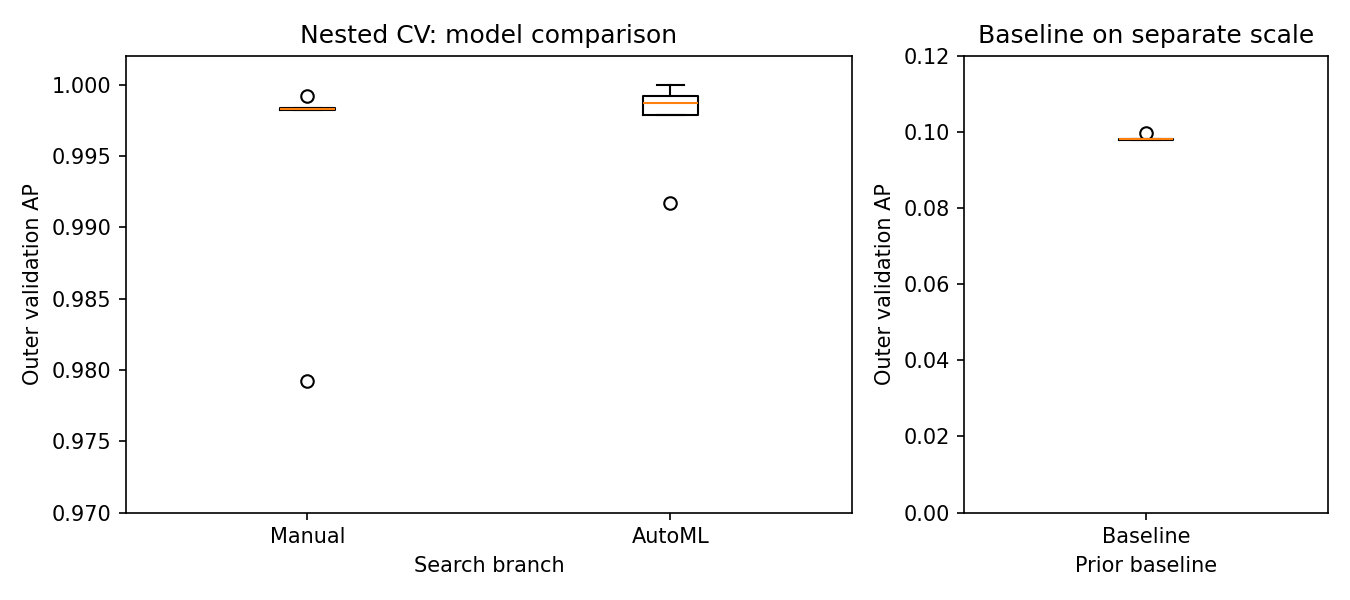

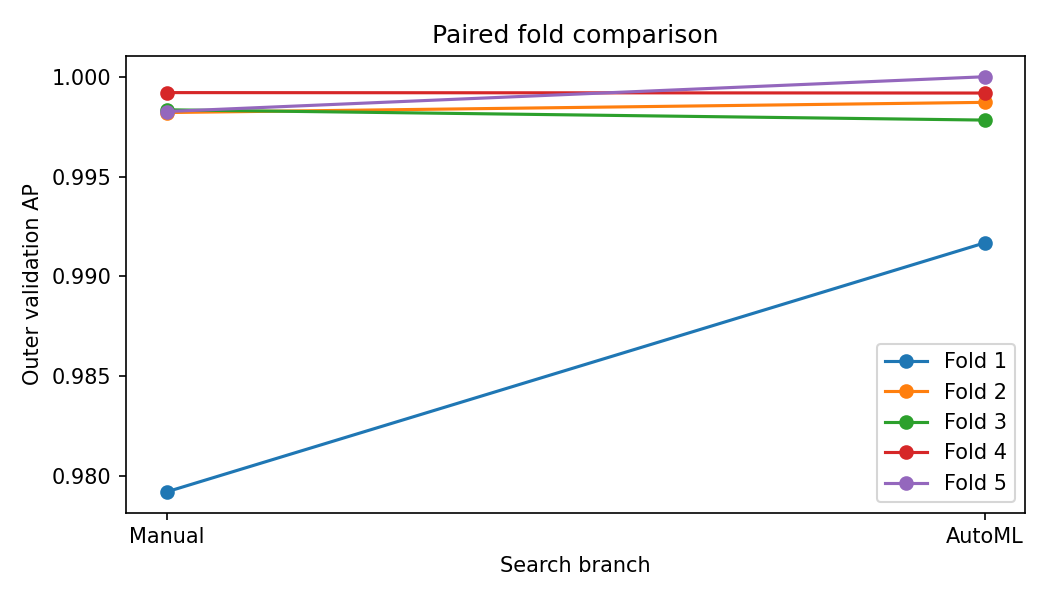

In [4]:
display(table('fold_metrics').round(6))
display(table('cv_summary').round(6))
display(record('paired_comparison'))
picture('01_ap_distribution')
picture('02_paired_ap')
oof=table('oof_predictions')
assert len(oof)==3058 and oof.id.is_unique and not oof.isna().any().any()
for row in table('fold_metrics').itertuples():
    g=oof[oof.fold.eq(row.fold)]
    assert np.isclose(E.probability_metrics(g.y,g[row.branch])['ap'],row.ap)

Обидві гілки порівнюються з Dummy prior. Рішення спирається на парну різницю та наперед заданий ε.
П'ять залежних fold-ів — малий матеріал для невизначеності; bootstrap тут описує мінливість середніх
на цих fold-ах, а не дає незалежний популяційний інтервал. Нуль усередині інтервалу не доводить рівність.

## 4. Стійкість пошуку й OOF-поведінка
Три фінальні searches змінюють seed splitter та FLAML; усі моделі з випадковістю мають random_state=42.
Перший seed=42 визначений операційним заздалегідь; інші не використовуються для перевибору після test.
Розбіжність фінальних моделей на train — описова, оптимістична для узагальнення; якість оцінюється outer OOF.

,seed,branch,family,inner_ap,params
0,42,manual,rf,0.997523,"{""n_estimators"": 64, ""max_depth"": null, ""min_s..."
1,42,automl,extra_tree,0.998782,"{""n_estimators"": 32, ""max_depth"": 10, ""min_sam..."
2,43,manual,rf,0.997030,"{""n_estimators"": 64, ""max_depth"": null, ""min_s..."
3,43,automl,kneighbor,0.995834,"{""n_neighbors"": 3, ""weights"": ""distance""}"
4,44,manual,rf,0.998917,"{""n_estimators"": 64, ""max_depth"": 10, ""min_sam..."
5,44,automl,rf,0.998324,"{""n_estimators"": 32, ""max_depth"": 10, ""min_sam..."


{'on': 'full train; descriptive fitted-model comparison, not a generalization estimate',
 'pairwise_disagreement': {'manual': [0.0013080444735120995,
   0.0013080444735120995,
   0.0],
  'automl': [0.0003270111183780249, 0.0003270111183780249, 0.0]}}

,category,n
0,both_correct,3021
1,both_wrong,21
2,only_manual_correct,10
3,only_automl_correct,6


,id,y,fold,manual,automl,baseline,category,probability_gap
0,2225,1,0,0.983019,0.349810,0.098528,only_manual_correct,0.633209
1,3235,1,4,0.998617,0.459690,0.098488,only_manual_correct,0.538927
2,898,1,4,0.994258,0.460916,0.098488,only_manual_correct,0.533343
3,1178,1,4,0.999791,0.473656,0.098488,only_manual_correct,0.526135
4,1112,1,4,0.999869,0.483710,0.098488,only_manual_correct,0.516159


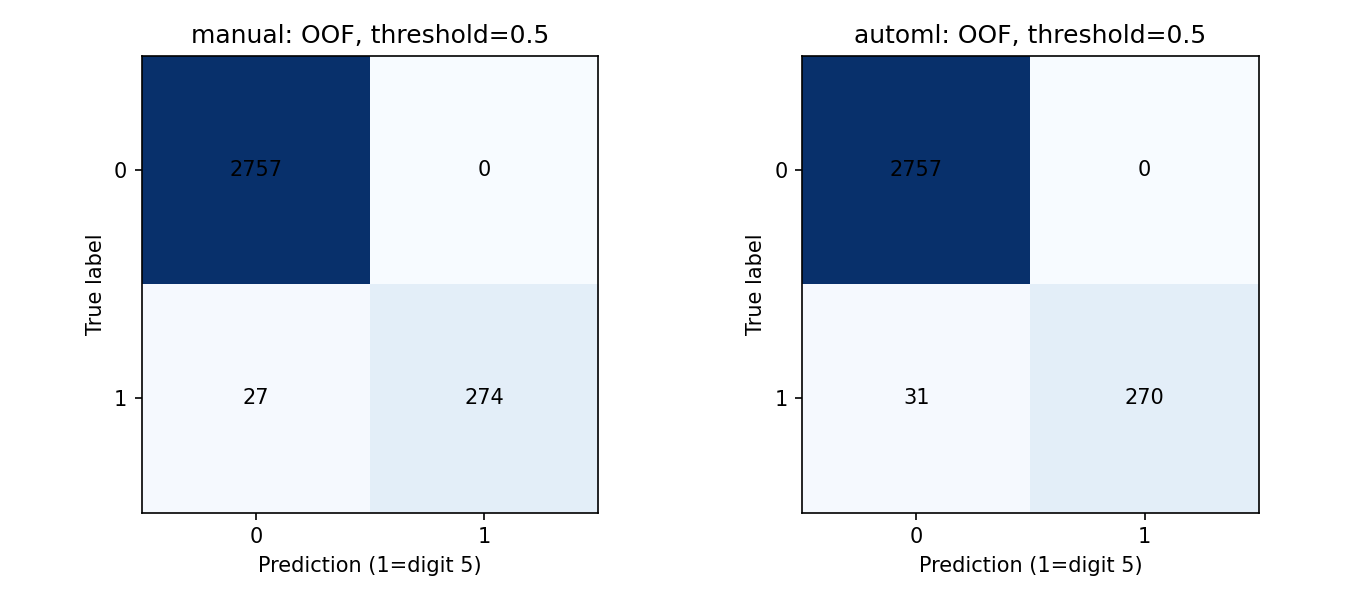

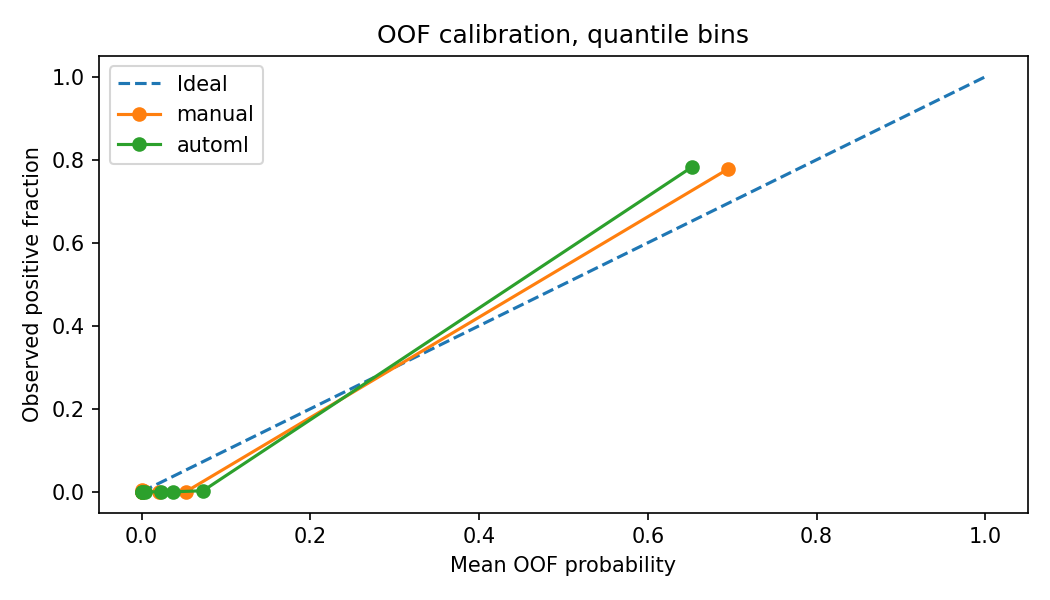

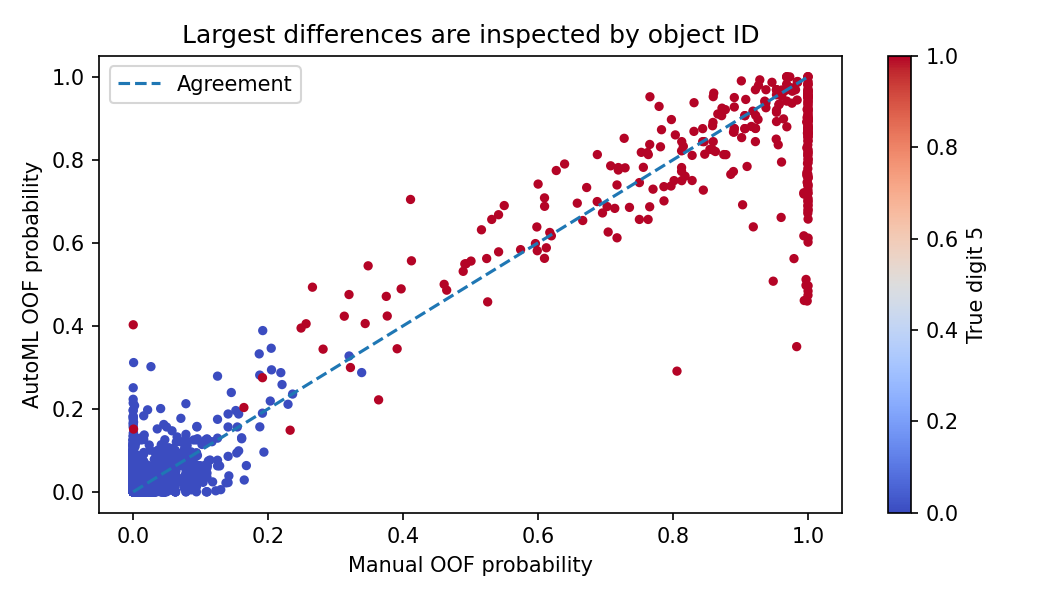

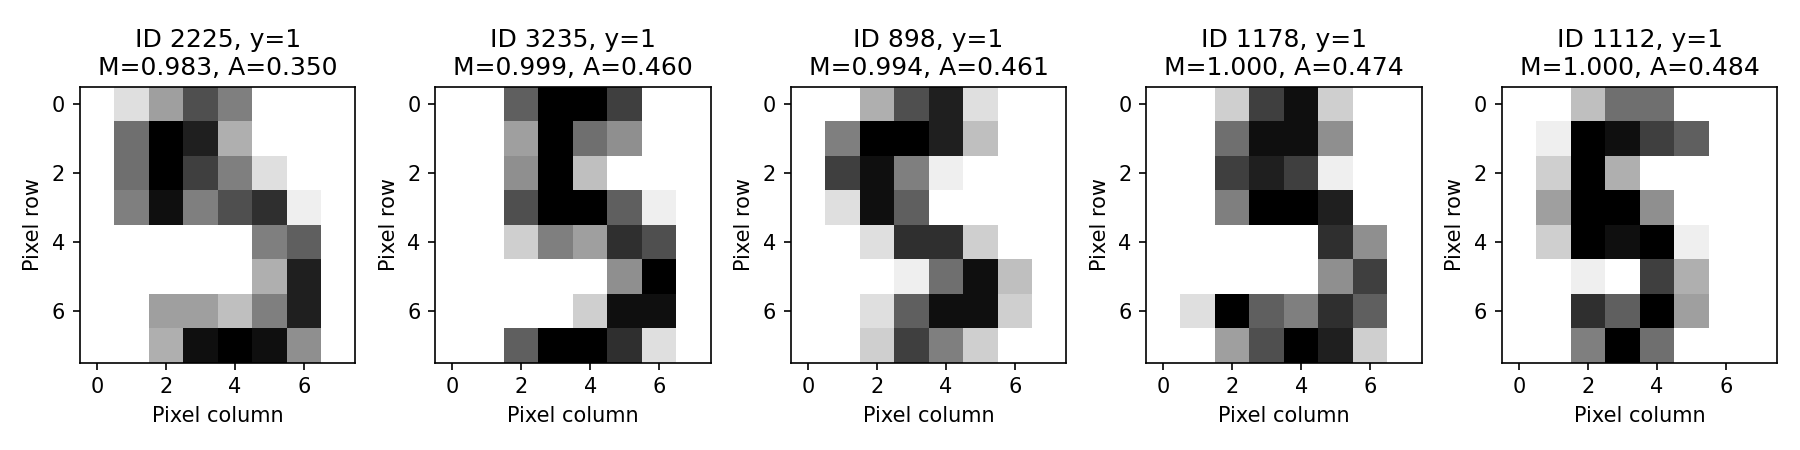

In [5]:
display(table('search_stability').round(6))
display(record('seed_disagreement'))
display(table('behavior_summary'))
display(table('largest_disagreements').round(6))
picture('04_confusion_matrices')
picture('03_calibration')
picture('06_probability_disagreement')
picture('07_disagreement_objects')

Стійкість сімейства та параметрів оцінюється за трьома searches у таблиці вище.
OOF-категорії відрізняють «дві неправильні» від «дві правильні»: сама згода не є якістю.
Великі розбіжності перевіряються за конкретними ID, істинним класом, ймовірностями та зображенням.
Висока прогнозована ймовірність не є гарантією; calibration plot і Brier перевіряють інший аспект, ніж AP.

## 5. Важливість на відкладених folds
Permutation importance рахується тільки на outer-validation, 5 перестановок, seed=42.
Показую середні top-10 та Jaccard. Корельовані пікселі можуть ділити важливість; мінусове падіння можливе через шум.
Це чутливість прогнозу, а не причинний ефект пікселя.

branch,automl,manual
feature,,
pixel_2_5,0.194482,0.273506
pixel_5_2,0.014942,0.037429
pixel_0_5,0.013418,0.016827
pixel_2_4,0.002996,0.008926
pixel_0_6,0.004113,0.004536
pixel_4_4,0.000682,0.003506
pixel_2_2,0.002194,0.002561
pixel_5_3,0.003708,0.001757
pixel_2_6,0.001390,0.001703


branch,automl,manual
feature,,
pixel_2_5,0.194482,0.273506
pixel_5_2,0.014942,0.037429
pixel_0_5,0.013418,0.016827
pixel_0_6,0.004113,0.004536
pixel_5_3,0.003708,0.001757
pixel_2_4,0.002996,0.008926
pixel_2_2,0.002194,0.002561
pixel_1_5,0.001433,0.001503
pixel_2_6,0.001390,0.001703


Top-10 Jaccard: 0.8181818181818182


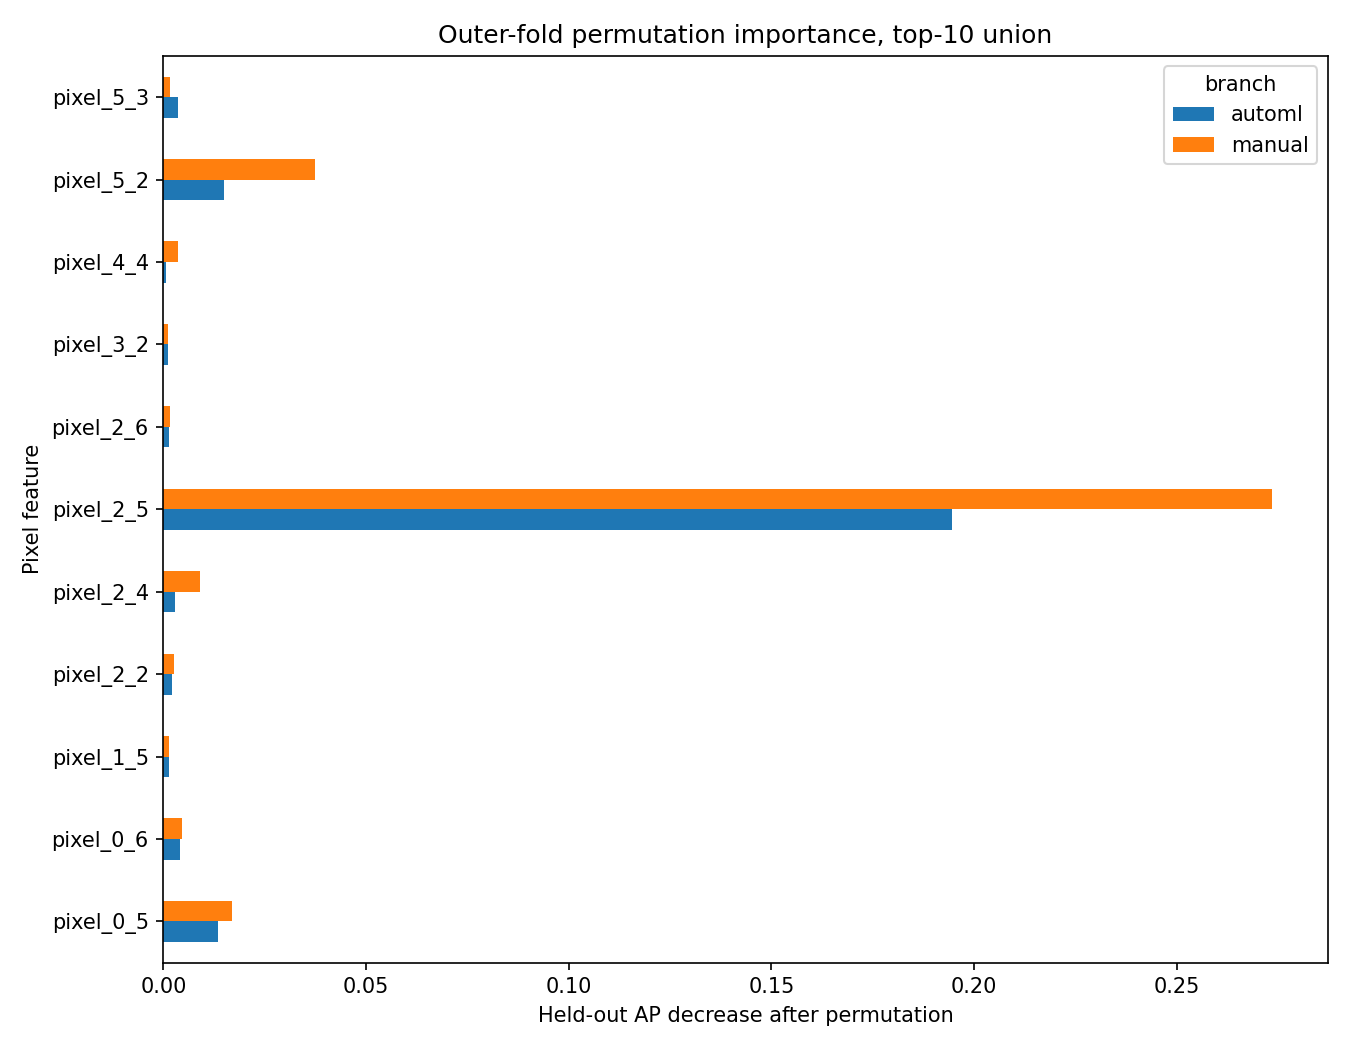

In [6]:
imp=table('permutation_importance').groupby(['branch','feature']).importance.mean().unstack('branch')
display(imp.nlargest(10,'manual').round(6))
display(imp.nlargest(10,'automl').round(6))
print('Top-10 Jaccard:',record('summary')['top10_jaccard'])
picture('05_permutation_importance')

## 6. Інженерні характеристики і рішення
Обидва фіналісти збережені як повні sklearn Pipeline без стану AutoML-пошуку.
Latency: 7 прогрівів, 45 вимірювань, один потік; пакети 1 і 256. Невелика різниця затримки залежить від машини.
Рішення записане до першого фінального predict(test), test_metrics_present=False; SHA-256 контролює незмінність.
Хеш сам по собі не доводить час створення або те, що людина ніколи не бачила даних.

In [7]:
display(table('engineering').round(6))
decision=record('decision_record');display(decision)
digest=E.sha256_file(ROOT/'results/decision_record.json')
print('Decision SHA-256:',digest)
assert digest==(ROOT/'results/decision.sha256').read_text().strip()
assert decision['test_metrics_present'] is False
eng=table('engineering')
if abs(decision['cv_evidence']['mean_difference'])<=decision['epsilon']:
    expected=eng.sort_values(['size_bytes','single_p95_ms','branch']).iloc[0].branch
    assert expected==decision['selected_branch']

,branch,search_seconds,fit_seconds,size_bytes,single_p50_ms,single_p95_ms,batch256_p50_ms,batch256_p95_ms
0,manual,6.829704,0.351429,156941,5.5504,7.18062,7.2112,9.37804
1,automl,2.949212,0.105698,149255,3.3269,4.89584,4.2517,6.14858


{'selected_branch': 'automl',
 'spec': {'family': 'extra_tree',
  'params': {'n_estimators': 32, 'max_depth': 10, 'min_samples_leaf': 1}},
 'reason': 'Mean AP difference within decision tie region; apply size, then single-object p95 latency, then Manual. This is not proof of equivalence.',
 'epsilon': 0.01,
 'cv_evidence': {'difference_automl_minus_manual': [0.012464890667521544,
   0.0005108780108781241,
   -0.0005149498124416008,
   -2.1761392729247042e-05,
   0.0017412935323382062],
  'mean_difference': 0.0028360702011134054,
  'bootstrap_interval_95': [-0.0001125088798927143, 0.007724203144492248],
  'epsilon': 0.01,
  'interval_limitation': 'Five dependent folds; descriptive fold bootstrap, not independent-sample CI or equivalence proof.'},
 'test_metrics_present': False,
 'config_sha256': '61e94714c3c41e03c98ff333e6938d9249fbfdbfe3972a5821035beae5934bd8',
 'limitations': ['single small historical Digits collection',
  'no writer IDs; writer-independent performance unverified',
  

Decision SHA-256: c2fd106f1bbd6d18514fea26bc2e3f899bd8a3ffa086e74d4b90ee0bec8c813e


Фактичне послідовне правило видно в config, engineering.csv і перевірці вище. Первинний JSON збережено без редагування після test.
На іншому обладнанні вибір у tie-регіоні може змінитись; для перевірки саме цього рішення слід читати збережені виміри.

## 7. Test і пакет передачі
Фінальний test оцінюється для вибраної гілки один раз у початковому запуску нового джерела.
Повторне відтворення коду знову обчислить оцінку, але не створює новий незалежний експеримент.

In [8]:
display(record('test_metrics'))
t=table('test_predictions');actual=E.probability_metrics(t.y,t.probability)
for key,value in actual.items(): assert np.isclose(value,record('test_metrics')[key])
print('Handoff files:',sorted(p.name for p in (ROOT/'handoff').iterdir()))
ex=json.loads((ROOT/'handoff/inference_example.json').read_text())
import joblib
from inference import predict
loaded=joblib.load(ROOT/'handoff/pipeline.joblib')
np.testing.assert_allclose(predict(loaded,ex['input']),ex['expected_probability'],rtol=1e-10,atol=1e-12)
assert record('test_metrics')['decision_sha256']==digest

{'branch': 'automl',
 'n': 765,
 'positive_n': 75,
 'threshold': 0.5,
 'ap': 0.9936444845929939,
 'roc_auc': 0.9989371980676328,
 'f1': 0.9583333333333334,
 'precision': 1.0,
 'recall': 0.92,
 'balanced_accuracy': 0.96,
 'brier': 0.010467026070698202,
 'log_loss': 0.05293371447498632,
 'confusion_matrix': [[690, 0], [6, 69]],
 'decision_sha256': 'c2fd106f1bbd6d18514fea26bc2e3f899bd8a3ffa086e74d4b90ee0bec8c813e'}

Handoff files: ['MODEL_CARD.md', 'config.json', 'cv_metrics.csv', 'data_provenance.json', 'data_schema.json', 'decision.sha256', 'decision_record.json', 'environment.json', 'inference.py', 'inference_example.json', 'pipeline.joblib', 'requirements.txt', 'split_ids.csv', 'test_metrics.json']


## 8. Висновок
Гіпотезу «найбільша середня AP автоматично визначає кращу інженерну модель» відхилено заданим ε і tie-break.
Manual зберігає сімейство RF у трьох searches, але параметри змінюються. AutoML обирає три різні сімейства:
Extra Trees, KNN і RF; гіпотезу про стійкість сімейства AutoML відхилено, навіть за невеликої розбіжності train-прогнозів.
Фактичні test AP, F1, recall і матриця помилок наведені вище; модель після test не змінюється.
Порушення незалежності початкового smoke-test виправлено новим джерелом. Немає writer-ID для групового поділу, історична колекція мала.
До ЛР № 7 передано модель, схему, конфігурацію, split, результати, model card, залежності й контрольний інференс.
Потрібні незалежні автори/сканери та перевірка порога для реального OCR-сценарію. Команди й тести — у README.